# 02 — Dari Citra Mentah ke Turunan DCAN: ABIDE I dan ABIDE II (sMRI Surface & rs-fMRI)

Notebook ini bertujuan untuk mengeksplorasi proses transformasi data dari **citra mentah (*raw data*)** menuju **turunan terstandardisasi (*DCAN derivatives*)** berbasis pipeline **ABCD-HCP** pada dataset ABIDE I dan ABIDE II:

1. **Konsep Pipeline ABCD-HCP (DCAN)**: Unifikasi pemrosesan ABIDE I dan II ke pipeline yang identik dan transisi ke representasi permukaan korteks (*surface-based fsLR32k*).
2. **Eksplorasi Struktural sMRI**: Perbandingan T1w raw vs segmentasi 113 label (`aparc+aseg`) dan rekonstruksi morfometri 3D (ketebalan, sulkus, kelengkungan).
3. **Eksplorasi Fungsional rs-fMRI**: Pembersihan baseline drift dan pergerakan kepala menjadi deret waktu bersih 379 parcel atlas HCP-MMP.
4. **Citra Raw ABIDE II (bagian 7)**: 2 subjek contoh dengan protokol berbeda (TR 0,475 s dan 2 s), dibandingkan dengan ABIDE I. Seluruh raw ABIDE II (±110 GB) tidak diunduh; penelitian memakai turunan DCAN.
5. **Manajemen Gerakan Kepala (FD < 0.3 mm)**: Masker pergerakan kepala, kurva retensi data, dan syarat kestabilan minimal 180 detik.
6. **Karakteristik ABIDE II & Matriks FC**: Akuisisi cepat (*multiband EPI* TR 0.475 s), matriks konektivitas fungsional (FC), dan heterogenitas multi-situs.
7. **Data Fenotipik & Alur Kohort Final**: Evaluasi demografi tanpa kebocoran label (*no data leakage*) dan tahapan seleksi berjenjang hingga 1.638 subjek.

## 1. Apa itu DCAN dan Pipeline ABCD-HCP?

Pipeline **ABCD-HCP (DCAN Labs)** mengintegrasikan *minimal preprocessing* Human Connectome Project dengan pembersihan sinyal BOLD tingkat lanjut (regresi derau fisiologis WM/CSF, 24 parameter gerakan, filter pernapasan, dan band-pass $0.008–0.09\text{ Hz}$).

Keuntungan utamanya adalah **menstandarkan ABIDE I dan ABIDE II dengan satu pipeline yang sama persis**, memindahkan analisis dari voxel 3D ke permukaan korteks 2D (*fsLR32k*), serta menyediakan fitur morfometri struktural untuk skenario multimodal.

| Karakteristik | PCP (C-PAC) | DCAN (ABCD-HCP) |
| :--- | :--- | :--- |
| **Cakupan Dataset** | Hanya ABIDE I | **ABIDE I dan ABIDE II** |
| **Konsistensi Pipeline** | Bervariasi | **Sama persis** (bebas efek batch software) |
| **Ruang Analisis Korteks** | Volume 3D (Voxel MNI) | **Permukaan 2D (fsLR32k / CIFTI)** |
| **Fitur sMRI** | Intensitas voxel kasar | **Rekonstruksi Mesh, Ketebalan, Sulkus, Kelengkungan** |
| **Filter Gerakan** | Standar | **Respiratory-filtered FD Masking** |

## 2. Tahapan Alur Pemrosesan ABCD-HCP

Berikut adalah alur transformasi dari citra mentah scanner hingga berkas turunan DCAN yang digunakan dalam penelitian:

```
 CITRA RAW (Scanner)                           TAHAPAN PIPELINE ABCD-HCP                        BERKAS TURUNAN DCAN
 ───────────────────                           ─────────────────────────                        ───────────────────
 T1w (sMRI 3D)  ─────►  1. PreFreeSurfer  : Denoising ANTs, alignment ACPC
                        2. FreeSurfer     : Segmentasi jaringan & rekonstruksi mesh      ──► Segmentasi: `*_space-ACPC_dseg.nii.gz`
                        3. PostFreeSurfer : Registrasi sferis fsLR32k (32k titik)        ──► Morfometri: `thickness`, `curv`, `sulc`
                                                                                         ──► Mesh: `midthickness.surf.gii`
 rs-fMRI (4D) ───────►  4. FMRIVolume     : Koreksi gerakan, registrasi MNI
                        5. FMRISurface    : Pemetaan volume ke grayordinate permukaan
                        6. DCANBOLDProc.  : Regresi derau, band-pass filter, parselasi   ──► Masker Gerakan: `*_motion_mask.mat`
                                            atlas HCP (379 parcel)                       ──► Time Series: `*_timeseries.ptseries.nii`
```

| Berkas DCAN | Isi Data | Peran di Pipeline Tugas Akhir |
| :--- | :--- | :--- |
| `..._atlas-HCP2016_desc-filtered_timeseries.ptseries.nii` | Deret waktu fMRI bersih per parcel (379 ROI) | Matriks FC & Tangent FC (Skenario 1–4) |
| `..._desc-filtered_motion_mask.mat` | FD per frame & daftar frame yang dibuang | QC gerakan & seleksi kohort (nb 21) |
| `..._space-fsLR32k_thickness/curv/sulc.dscalar.nii` | Ketebalan, kelengkungan, kedalaman sulkus per simpul | Fitur morfometri korteks (nb 23, S2–S4) |
| `..._hemi-L/R_..._midthickness.surf.gii` | Geometri mesh permukaan di ruang subjek | Luas area per parcel & visualisasi 3D |
| `..._space-ACPC_dseg.nii.gz` | Segmentasi 113 struktur anatomis (FreeSurfer) | Validasi anatomis subkortikal |

## 3. Persiapan & Verifikasi Ketersediaan Data

In [1]:
from pathlib import Path
import glob
import warnings
import numpy as np
import pandas as pd
import nibabel as nib
import scipy.io
import matplotlib.pyplot as plt
from nilearn import plotting
from IPython.display import display
warnings.filterwarnings("ignore")

# Setup direktori kerja
ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent

RAW_DIR = ROOT / "data" / "raw"
DCAN_DIR = ROOT / "data" / "raw_dcan"
PROC = ROOT / "data" / "processed"
TABEL_DIR = ROOT / "result" / "tabel"
FIG_DIR = ROOT / "result" / "figure"
FIG_DIR.mkdir(parents=True, exist_ok=True)

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
STRUKTUR = {"CIFTI_STRUCTURE_CORTEX_LEFT": "L", "CIFTI_STRUCTURE_CORTEX_RIGHT": "R"}

def cari(folder, pola):
    hasil = sorted(glob.glob(str(folder / pola)))
    assert hasil, f"Tidak ada berkas {pola} di {folder}"
    return hasil[0]

def ke_32k(img):
    x, ax = img.get_fdata()[0], img.header.get_axis(1)
    hasil = {}
    for s, h in STRUKTUR.items():
        m = (ax.name == s)
        arr = np.full(ax.nvertices[s], np.nan)
        arr[ax.vertex[m]] = x[m]
        hasil[h] = arr
    return hasil

def baca_gerak(berkas):
    md_ = np.atleast_1d(scipy.io.loadmat(berkas, squeeze_me=True, struct_as_record=False)["motion_data"])
    return {round(float(e.FD_threshold), 2): e for e in md_}

def ukuran_gb(folder):
    return sum(f.stat().st_size for f in Path(folder).rglob("*") if f.is_file()) / 1e9

# Ringkasan status data
ringkas = pd.DataFrame({
    "Dataset": ["ABIDE I", "ABIDE II"],
    "Folder subjek di server DCAN": [1092, 1032],
    "Folder subjek yang diunduh": [len(list((DCAN_DIR / d).glob("sub-*"))) for d in ("abide1", "abide2")],
    "Ukuran di penyimpanan (GB)": [round(ukuran_gb(DCAN_DIR / d), 1) for d in ("abide1", "abide2")],
    "Subjek di kohort akhir": [int((kohort["dataset"] == d).sum()) for d in ("abide1", "abide2")],
})
display(ringkas.style.set_caption("Status Ketersediaan Turunan DCAN: Server, Unduhan, dan Kohort Akhir"))

,Dataset,Folder subjek di server DCAN,Folder subjek yang diunduh,Ukuran di penyimpanan (GB),Subjek di kohort akhir
0,ABIDE I,1092,979,5.800000,886
1,ABIDE II,1032,991,5.700000,752


## 4. Komparasi Struktural sMRI: T1w Raw vs Segmentasi DCAN Subjek Caltech 0051457

Di bawah ini kita membandingkan citra T1w mentah (masih memuat tengkorak, leher, dan orientasi asli pemindai) dengan hasil segmentasi DCAN (`space-ACPC_dseg`) yang telah disejajarkan ke ruang ACPC ($1.0\text{ mm}$ isotropik) dan dipetakan ke 113 label anatomis FreeSurfer (`aparc+aseg`).

,Citra,Dimensi Voxel,Resolusi Spasial (mm),Jumlah Struktur
0,T1 raw (mprage),"(176, 256, 256)",1.00 x 1.00 x 1.00,– (Intensitas mentah)
1,Segmentasi DCAN (dseg),"(182, 218, 182)",1.00 x 1.00 x 1.00,111 label anatomis


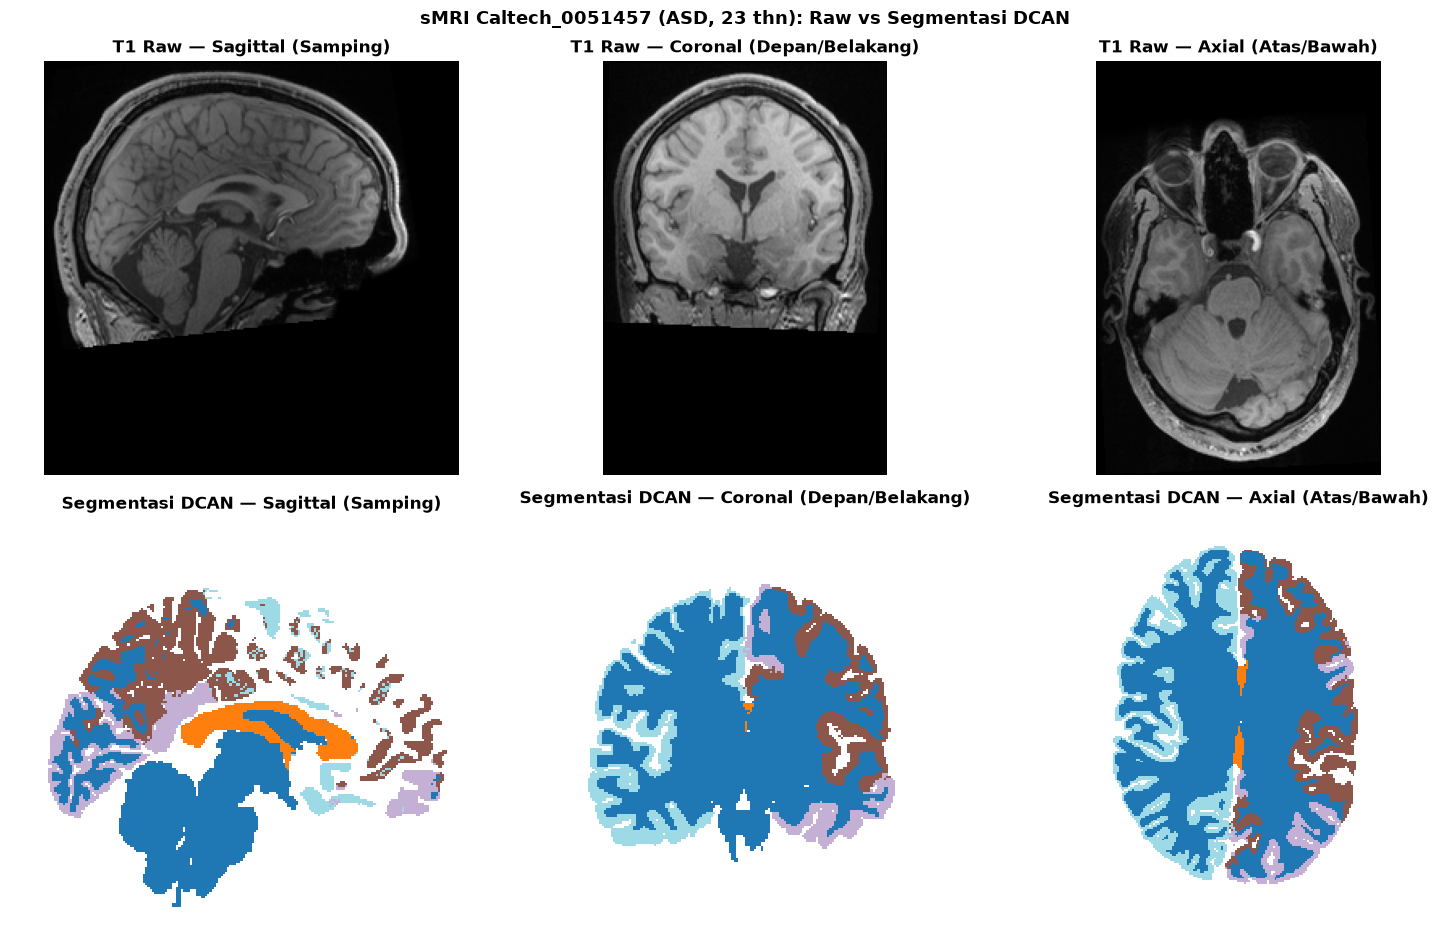

In [2]:
CONTOH = kohort[kohort["FILE_ID"] == "Caltech_0051457"].iloc[0]
d_dcan = DCAN_DIR / "abide1" / CONTOH["sub"]

t1_raw = nib.load(RAW_DIR / "Caltech" / "0051457" / "session_1" / "anat_1" / "mprage.nii.gz")
dseg = nib.load(cari(d_dcan, "*_space-ACPC_dseg.nii.gz"))
T1, S = t1_raw.get_fdata(), dseg.get_fdata()

info_smri = pd.DataFrame({
    "Citra": ["T1 raw (mprage)", "Segmentasi DCAN (dseg)"],
    "Dimensi Voxel": [str(T1.shape), str(S.shape)],
    "Resolusi Spasial (mm)": [
        " x ".join(f"{v:.2f}" for v in t1_raw.header.get_zooms()[:3]),
        " x ".join(f"{v:.2f}" for v in dseg.header.get_zooms()[:3])
    ],
    "Jumlah Struktur": ["– (Intensitas mentah)", f"{len(np.unique(S)) - 1} label anatomis"]
})
display(info_smri)

fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
irisan_list = [
    ("Sagittal (Samping)", lambda v: v[v.shape[0] // 2, :, :]),
    ("Coronal (Depan/Belakang)", lambda v: v[:, v.shape[1] // 2, :]),
    ("Axial (Atas/Bawah)", lambda v: v[:, :, v.shape[2] // 2])
]

for j, (nama, sl) in enumerate(irisan_list):
    # Baris 1: T1 Raw
    axes[0, j].imshow(np.rot90(sl(T1)), cmap="gray")
    axes[0, j].set_title(f"T1 Raw — {nama}", fontweight="bold")
    axes[0, j].axis("off")
    
    # Baris 2: Segmentasi DCAN
    seg = np.rot90(sl(S)).astype(float)
    seg[seg == 0] = np.nan
    axes[1, j].imshow(seg, cmap="tab20", interpolation="nearest")
    axes[1, j].set_title(f"Segmentasi DCAN — {nama}", fontweight="bold")
    axes[1, j].axis("off")

status_diag = "ASD" if CONTOH["label"] == 1 else "Kontrol"
fig.suptitle(f"sMRI {CONTOH['FILE_ID']} ({status_diag}, {CONTOH['usia']:.0f} thn): Raw vs Segmentasi DCAN", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "01b_1_smri_raw_vs_dseg.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Rekonstruksi Geometri Permukaan Korteks & Peta Morfometri (fsLR32k)

Tahap PostFreeSurfer merekonstruksi permukaan korteks sebagai *mesh* 3D dengan resolusi standar **fsLR32k** (32.492 simpul per belahan otak). Di setiap simpul dihitung tiga metrik morfometri biologis:
- **Ketebalan Korteks (*Cortical Thickness*, $mm$)**: Jarak dari permukaan materi putih ke permukaan pial.
- **Kedalaman Sulkus (*Sulcal Depth*)**: Kedalaman lipatan (positif di sulkus, negatif di girus).
- **Kelengkungan (*Curvature*)**: Derajat kelengkungan rata-rata lokal permukaan korteks.

,Peta Morfometri,Total Simpul (L),Dinding Medial (NaN),Rata-rata,Rentang 1–99%
0,Ketebalan (mm),32492,2796,2.501000,0.99 – 4.46
1,Kedalaman Sulkus,32492,0,-0.073000,-1.45 – 1.15
2,Kelengkungan,32492,2796,0.016000,-0.27 – 0.37


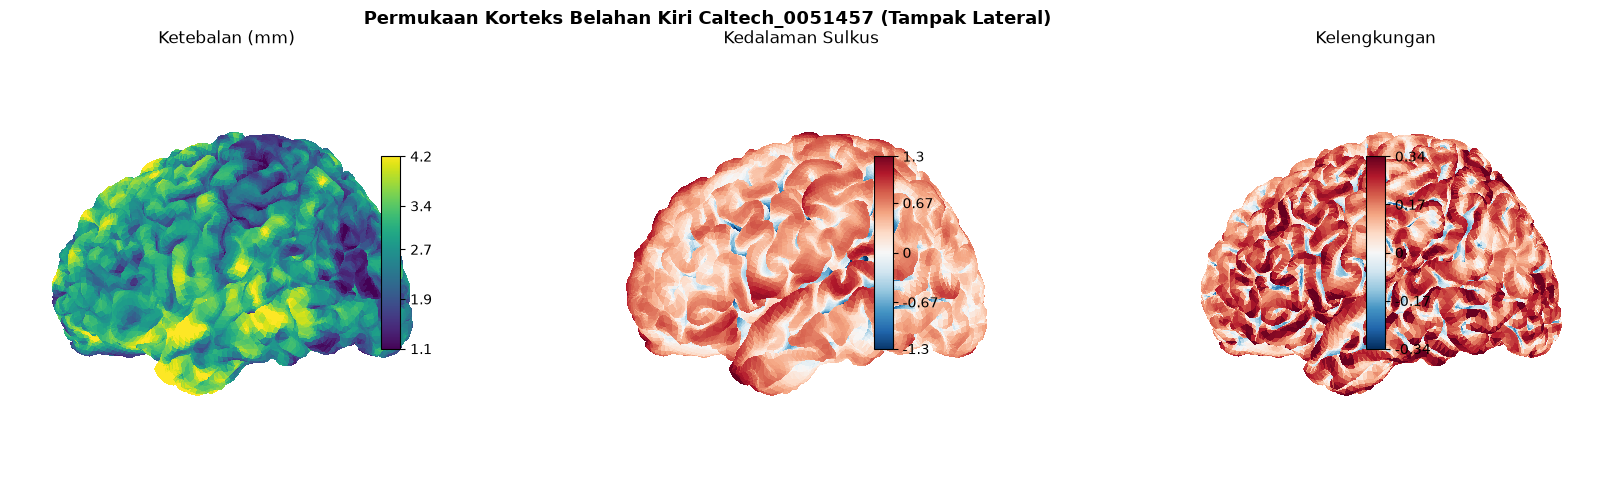

In [3]:
mesh = nib.load(cari(d_dcan, "*_hemi-L_space-T1w_mesh-fsLR32k_midthickness.surf.gii"))
koord, segitiga = mesh.agg_data("NIFTI_INTENT_POINTSET"), mesh.agg_data("NIFTI_INTENT_TRIANGLE")

PETA = {
    "Ketebalan (mm)": ke_32k(nib.load(cari(d_dcan, "*_space-fsLR32k_thickness.dscalar.nii")))["L"],
    "Kedalaman Sulkus": ke_32k(nib.load(cari(d_dcan, "*_space-fsLR32k_sulc.dscalar.nii")))["L"],
    "Kelengkungan": ke_32k(nib.load(cari(d_dcan, "*_space-fsLR32k_curv.dscalar.nii")))["L"]
}

df_morf = pd.DataFrame({
    "Peta Morfometri": list(PETA.keys()),
    "Total Simpul (L)": [len(v) for v in PETA.values()],
    "Dinding Medial (NaN)": [int(np.isnan(v).sum()) for v in PETA.values()],
    "Rata-rata": [float(np.nanmean(v)) for v in PETA.values()],
    "Rentang 1–99%": [f"{np.nanpercentile(v, 1):.2f} – {np.nanpercentile(v, 99):.2f}" for v in PETA.values()]
})
display(df_morf.round(3).style.set_caption(f"Mesh fsLR32k: {len(koord):,} titik simpul, {len(segitiga):,} poligon segitiga"))

fig, axes = plt.subplots(1, 3, figsize=(18, 5), subplot_kw={"projection": "3d"})
cmaps = ["viridis", "RdBu_r", "RdBu_r"]

for ax, (nama, peta), cmap in zip(axes, PETA.items(), cmaps):
    v = np.nan_to_num(peta, nan=np.nanmedian(peta))
    lo, hi = np.nanpercentile(peta, [2, 98])
    vmax = hi if cmap == "viridis" else max(abs(lo), abs(hi))
    vmin = lo if cmap == "viridis" else None
    
    plotting.plot_surf_stat_map(
        (koord, segitiga), v, hemi="left", view="lateral",
        cmap=cmap, vmin=vmin, vmax=vmax,
        symmetric_cbar=(cmap != "viridis"),
        colorbar=True, axes=ax, figure=fig, title=nama
    )

fig.suptitle(f"Permukaan Korteks Belahan Kiri {CONTOH['FILE_ID']} (Tampak Lateral)", fontsize=13, fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "01b_2_permukaan_korteks.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Komparasi Fungsional rs-fMRI: Voxel 4D Raw vs Turunan Terparselasi DCAN

- **Raw (Sebelum)**: Volume 4D (~60.000 voxel otak) yang masih dipengaruhi *baseline drift*, pernapasan, dan artefak pergerakan kepala.
- **DCAN (Sesudah)**: Sinyal BOLD pasca-regresi derau fisiologis (WM/CSF/gerakan), band-pass filter $0.008–0.09\text{ Hz}$, dan dirata-ratakan ke 379 parcel atlas HCP-MMP.

Area merah pada grafik di bawah menandai frame yang teridentifikasi bergerak ($\text{FD} \ge 0.3\text{ mm}$) dan dibuang saat perhitungan konektivitas.

,Dimensi,rs-fMRI Raw,DCAN ptseries (HCP)
0,Bentuk Array,"(64, 64, 34, 150) (Voxel 4D)","(150, 379) (2D)"
1,TR (detik),2.00 s,2.00 s
2,Jumlah Frame,150,150
3,Unit Data,"~55,705 voxel otak",379 parcel biologis


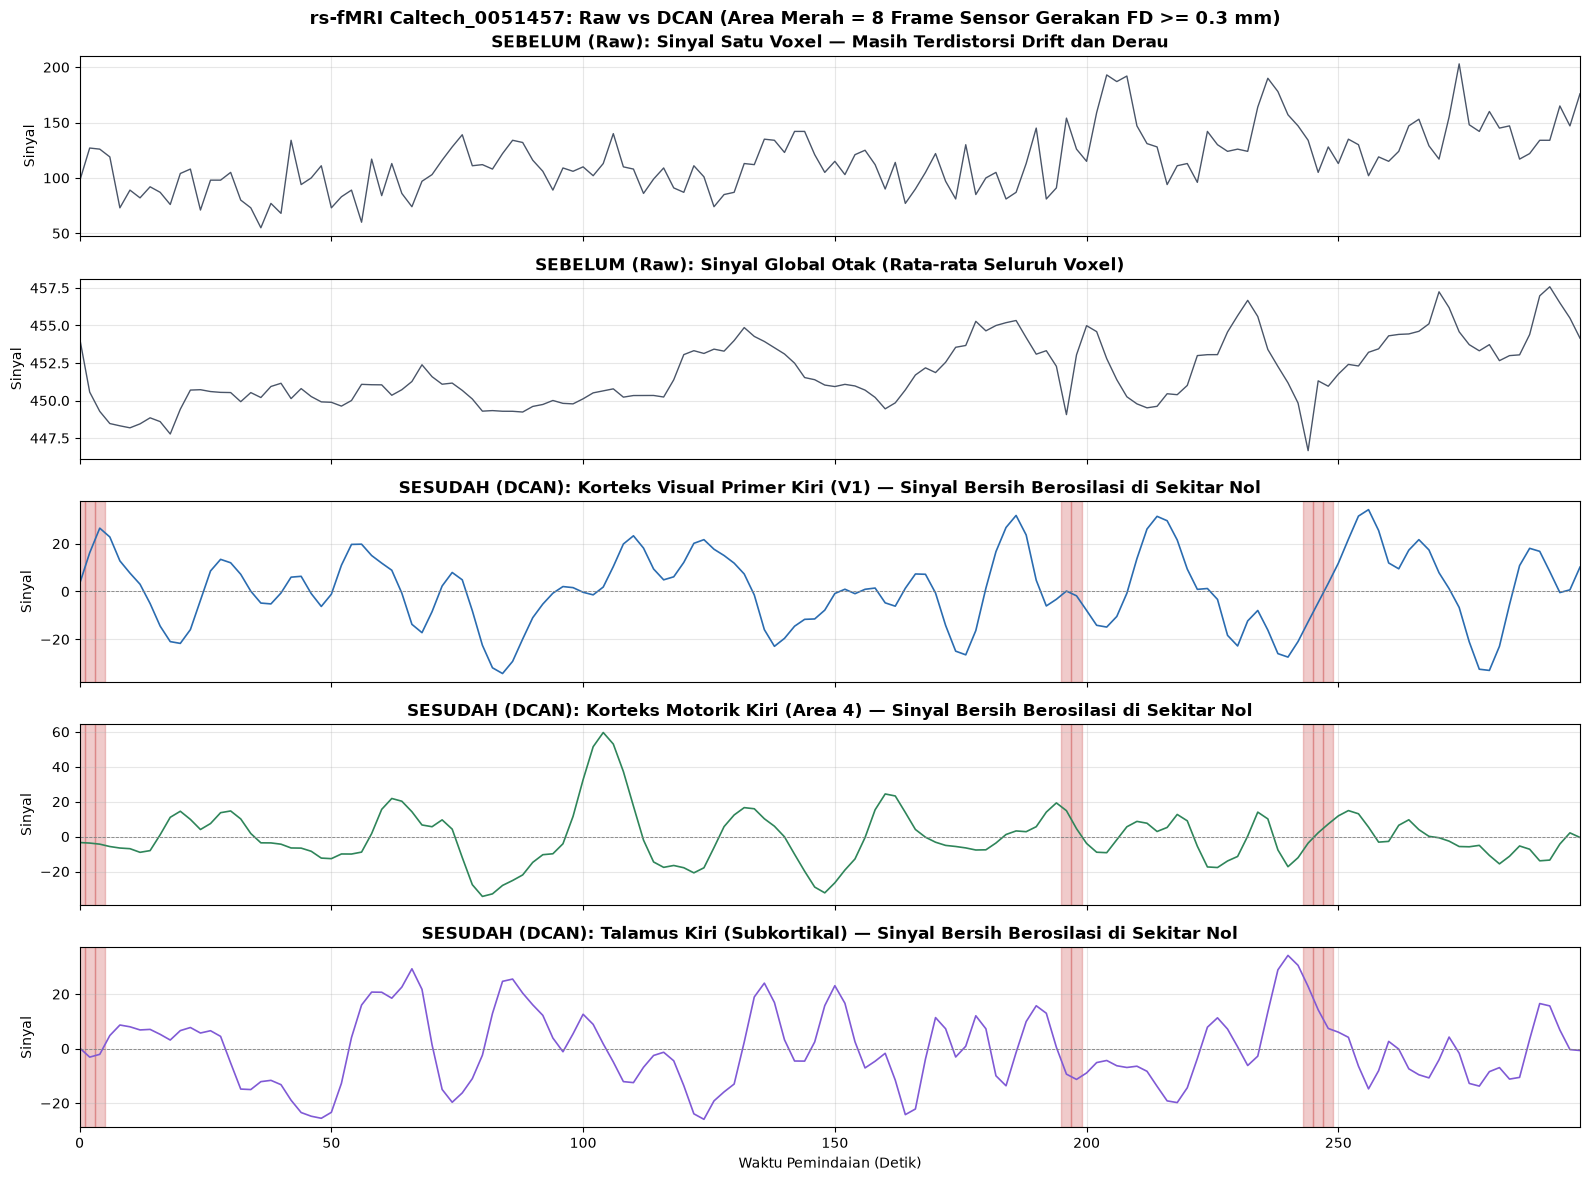

In [4]:
bold_raw = nib.load(RAW_DIR / "Caltech" / "0051457" / "session_1" / "rest_1" / "rest.nii.gz")
B = bold_raw.get_fdata(dtype=np.float32)

ts_img = nib.load(cari(d_dcan, "*HCP2016*_timeseries.ptseries.nii"))
TS = ts_img.get_fdata()                                           # (frame, parcel)
ax_waktu, ax_parcel = ts_img.header.get_axis(0), ts_img.header.get_axis(1)

masker_otak = B.mean(-1) > np.percentile(B.mean(-1), 60)
sinyal_global = B[masker_otak].mean(0)
voxel_tengah = np.argwhere(masker_otak)[len(np.argwhere(masker_otak)) // 2]

display(pd.DataFrame({
    "Dimensi": ["Bentuk Array", "TR (detik)", "Jumlah Frame", "Unit Data"],
    "rs-fMRI Raw": [f"{B.shape} (Voxel 4D)", f"{float(bold_raw.header.get_zooms()[3]):.2f} s", B.shape[3], f"~{int(masker_otak.sum()):,} voxel otak"],
    "DCAN ptseries (HCP)": [f"{TS.shape} (2D)", f"{float(ax_waktu.step):.2f} s", TS.shape[0], f"{TS.shape[1]} parcel biologis"]
}))

gerak = baca_gerak(cari(d_dcan, "*_motion_mask.mat"))
dibuang = np.asarray(gerak[0.3].frame_removal).astype(bool)

PARCEL_CONTOH = {
    "L_V1_ROI": "Korteks Visual Primer Kiri (V1)",
    "L_4_ROI": "Korteks Motorik Kiri (Area 4)",
    "THALAMUS_LEFT": "Talamus Kiri (Subkortikal)"
}
idx = {n: list(ax_parcel.name).index(n) for n in PARCEL_CONTOH}
TR1 = float(bold_raw.header.get_zooms()[3])
t = np.arange(B.shape[3]) * TR1

fig, axes = plt.subplots(2 + len(idx), 1, figsize=(16, 12), sharex=True)

# Sinyal Raw
axes[0].plot(t, B[tuple(voxel_tengah)], color="#4A5568", lw=1)
axes[0].set_title("SEBELUM (Raw): Sinyal Satu Voxel — Masih Terdistorsi Drift dan Derau", fontweight="bold")

axes[1].plot(t, sinyal_global, color="#4A5568", lw=1)
axes[1].set_title("SEBELUM (Raw): Sinyal Global Otak (Rata-rata Seluruh Voxel)", fontweight="bold")

# Sinyal DCAN
warna_list = ["#2B6CB0", "#2F855A", "#805AD5"]
for ax, (n, label), w in zip(axes[2:], PARCEL_CONTOH.items(), warna_list):
    ax.plot(t, TS[:, idx[n]], color=w, lw=1.2)
    for tf in t[dibuang]:
        ax.axvspan(tf - TR1 / 2, tf + TR1 / 2, color="#C53030", alpha=0.25)
    ax.axhline(0, color="gray", lw=0.6, linestyle="--")
    ax.set_title(f"SESUDAH (DCAN): {label} — Sinyal Bersih Berosilasi di Sekitar Nol", fontweight="bold")

for ax in axes:
    ax.set_ylabel("Sinyal")
    ax.grid(alpha=0.3)
    ax.set_xlim(0, t[-1])

axes[-1].set_xlabel("Waktu Pemindaian (Detik)")
fig.suptitle(f"rs-fMRI {CONTOH['FILE_ID']}: Raw vs DCAN (Area Merah = {dibuang.sum()} Frame Sensor Gerakan FD >= 0.3 mm)", fontweight="bold", fontsize=13)
plt.tight_layout()
fig.savefig(FIG_DIR / "01b_3_fmri_raw_vs_dcan.png", dpi=150, bbox_inches="tight")
plt.show()

del B

## 7. Citra Raw ABIDE II

Seluruh citra raw ABIDE II (±110 GB) tidak diunduh. Supaya data mentahnya tetap bisa dilihat, diunduh **2 subjek contoh** dengan `tools/download_contoh_raw_abide2.py` (±437 MB, `data/raw_abide2_contoh/`). Kedua subjek dipilih karena **protokolnya sangat berbeda**:

| Subjek | Situs | Protokol rs-fMRI |
| :--- | :--- | :--- |
| sub-28675 | ONRC_2 | *multiband*, TR **0,475 detik** |
| sub-29177 | NYU_1 | konvensional, TR **2 detik** (sama dengan sebagian besar ABIDE I) |

Keduanya dibandingkan dengan subjek ABIDE I dari bagian 4–6 (Caltech_0051457).

Format penamaan berkas ABIDE II mengikuti standar **BIDS** (`sub-XXXXX/ses-1/anat/…_T1w.nii.gz`, `…/func/…_bold.nii.gz`), berbeda dengan ABIDE I (`<situs>/<subjek>/session_1/anat_1/mprage.nii.gz`).

In [5]:
RAW2_DIR = ROOT / "data" / "raw_abide2_contoh"
CONTOH_RAW = {
    "Caltech_0051457 (ABIDE I)": (RAW_DIR / "Caltech" / "0051457" / "session_1" / "anat_1" / "mprage.nii.gz",
                                  RAW_DIR / "Caltech" / "0051457" / "session_1" / "rest_1" / "rest.nii.gz", "abide1", "sub-0051457"),
    "sub-28675 ONRC_2 (ABIDE II)": (RAW2_DIR / "ABIDEII-ONRC_2" / "sub-28675" / "ses-1" / "anat" / "sub-28675_ses-1_run-1_T1w.nii.gz",
                                    RAW2_DIR / "ABIDEII-ONRC_2" / "sub-28675" / "ses-1" / "func" / "sub-28675_ses-1_task-rest_acq-pedj_run-1_bold.nii.gz",
                                    "abide2", "sub-28675"),
    "sub-29177 NYU_1 (ABIDE II)": (RAW2_DIR / "ABIDEII-NYU_1" / "sub-29177" / "ses-1" / "anat" / "sub-29177_ses-1_run-1_T1w.nii.gz",
                                   RAW2_DIR / "ABIDEII-NYU_1" / "sub-29177" / "ses-1" / "func" / "sub-29177_ses-1_task-rest_run-1_bold.nii.gz",
                                   "abide2", "sub-29177"),
}
baris = []
for nama, (t1, bold, ds, sub) in CONTOH_RAW.items():
    a, b = nib.load(t1), nib.load(bold)
    tr = float(b.header.get_zooms()[3])
    dcan = kohort[(kohort["dataset"] == ds) & (kohort["sub"] == sub)]
    baris.append({"Subjek": nama, "T1: ukuran (voxel)": "×".join(map(str, a.shape)),
                  "T1: resolusi (mm)": "×".join(f"{v:.2f}" for v in a.header.get_zooms()[:3]),
                  "rs-fMRI: ukuran (x×y×z)": "×".join(map(str, b.shape[:3])), "rs-fMRI: resolusi (mm)": "×".join(f"{v:.1f}" for v in b.header.get_zooms()[:3]),
                  "TR (detik)": tr, "Frame (1 run raw)": b.shape[3], "Durasi 1 run (detik)": round(b.shape[3] * tr, 1),
                  "Frame di DCAN": int(dcan["total_frame"].iloc[0]) if len(dcan) else "-"})
display(pd.DataFrame(baris).style.set_caption("Protokol pemindaian: ABIDE I vs 2 contoh ABIDE II (dibaca dari header berkas raw)"))

,Subjek,T1: ukuran (voxel),T1: resolusi (mm),rs-fMRI: ukuran (x×y×z),rs-fMRI: resolusi (mm),TR (detik),Frame (1 run raw),Durasi 1 run (detik),Frame di DCAN
0,Caltech_0051457 (ABIDE I),176×256×256,1.00×1.00×1.00,64×64×34,3.5×3.5×3.5,2.000000,150,300.000000,150
1,sub-28675 ONRC_2 (ABIDE II),220×320×208,0.80×0.80×0.80,80×80×48,3.0×3.0×3.0,0.475000,947,449.800000,1894
2,sub-29177 NYU_1 (ABIDE II),128×256×256,1.33×1.00×1.00,64×80×33,3.0×3.0×4.0,2.000000,180,360.000000,180


**Cara membaca tabel:**
- **Resolusi T1 berbeda antar situs** (0,8–1,3 mm), dan resolusi serta TR rs-fMRI juga berbeda. Inilah sebabnya data mentah harus diolah dengan pipeline yang sama (DCAN) sebelum digabung: semua subjek dibawa ke ruang dan parcel yang sama.
- Subjek ONRC_2 punya 947 frame dalam 1 run raw, tetapi **1.894 frame di DCAN**. Subjek ini direkam **2 run**, dan DCAN menggabungkan keduanya (lihat bagian 9).

Gambar berikut menampilkan potongan tengah citra T1 raw ketiga subjek dalam orientasi yang sama (sagital, kepala menghadap kanan).

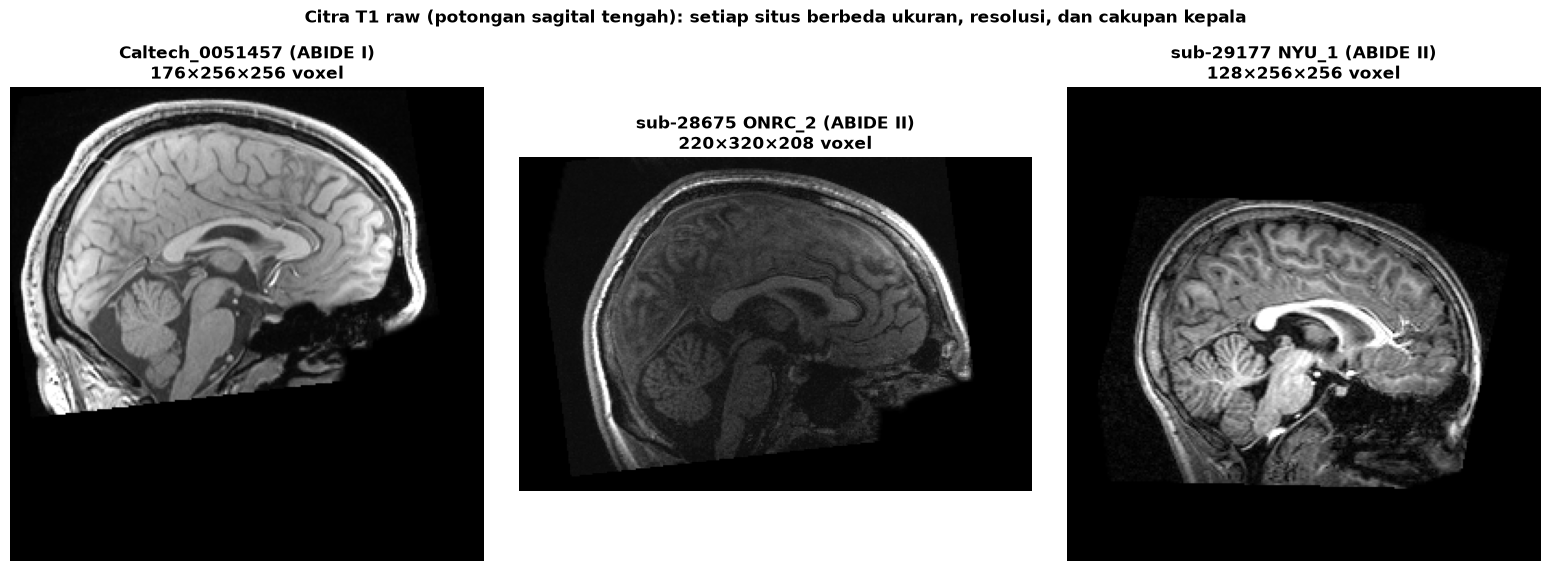

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (nama, (t1, _, _, _)) in zip(axes, CONTOH_RAW.items()):
    img = nib.as_closest_canonical(nib.load(t1))                       # orientasi baku RAS supaya ketiganya sejajar
    v = np.asarray(img.dataobj, dtype=np.float32)
    ax.imshow(np.rot90(v[v.shape[0] // 2]), cmap="gray", vmax=np.percentile(v, 99.5),
              aspect=img.header.get_zooms()[2] / img.header.get_zooms()[1])
    ax.set_title(f"{nama}\n{'×'.join(map(str, v.shape))} voxel", fontweight="bold"); ax.axis("off")
fig.suptitle("Citra T1 raw (potongan sagital tengah): setiap situs berbeda ukuran, resolusi, dan cakupan kepala", fontweight="bold", y=1.03)
plt.tight_layout()
fig.savefig(FIG_DIR / "01b_3b_t1_raw_abide1_vs_abide2.png", dpi=150, bbox_inches="tight")
plt.show()

Untuk rs-fMRI, ditampilkan **sinyal global** (rata-rata semua voxel otak) dari data raw ketiga subjek pada 180 detik pertama. Titik-titik menunjukkan saat setiap frame direkam. Pada TR 0,475 detik, frame direkam ±4× lebih rapat daripada TR 2 detik. Beberapa frame pertama setiap pemindaian tidak ditampilkan karena sinyalnya belum stabil (sinyal MRI butuh beberapa detik untuk mencapai keadaan tetap). Frame ini juga selalu dibuang oleh DCAN.

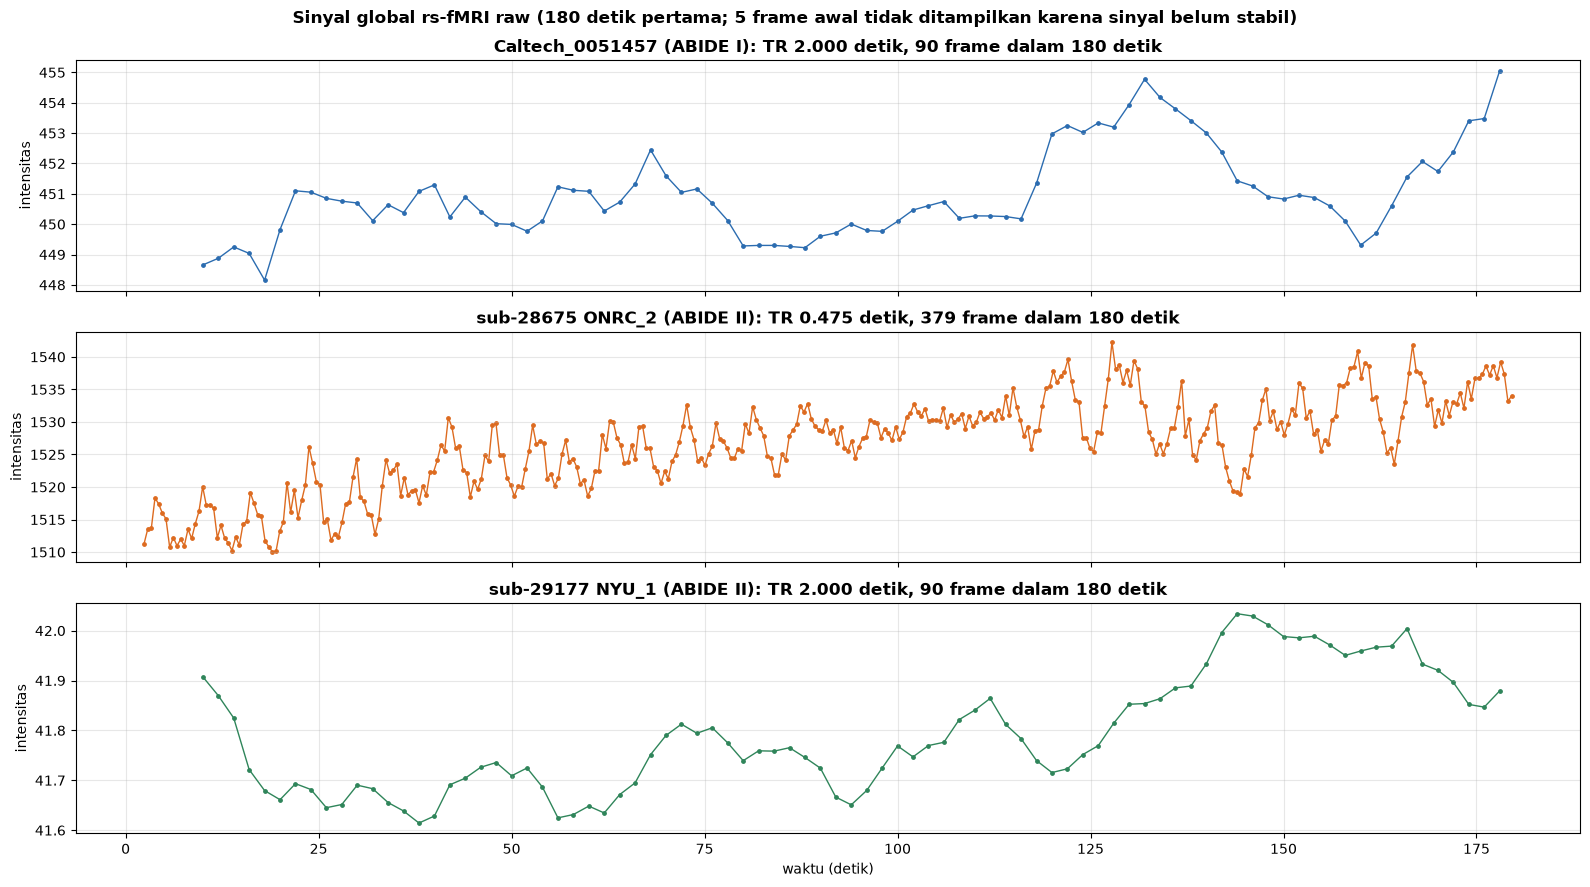

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(16, 9), sharex=True)
for ax, (nama, (_, bold, _, _)), w in zip(axes, CONTOH_RAW.items(), ["#2B6CB0", "#DD6B20", "#2F855A"]):
    img = nib.load(bold)
    tr = float(img.header.get_zooms()[3])
    n = min(img.shape[3], int(np.ceil(180 / tr)))
    V = np.asarray(img.dataobj[..., :n], dtype=np.float32)              # dibaca sekaligus (berkas .gz lambat bila dibaca per frame)
    otak = V[..., 0] > np.percentile(V[..., 0], 60)                     # perkiraan kasar voxel otak
    sinyal = V[otak].mean(0)
    del V
    t = np.arange(n) * tr
    awal = 5                                                            # frame awal: sinyal belum stabil (juga dibuang DCAN)
    ax.plot(t[awal:], sinyal[awal:], color=w, lw=1); ax.scatter(t[awal:], sinyal[awal:], s=6, color=w)
    ax.set_title(f"{nama}: TR {tr:.3f} detik, {n} frame dalam 180 detik", fontweight="bold"); ax.set_ylabel("intensitas"); ax.grid(alpha=0.3)
axes[-1].set_xlabel("waktu (detik)")
fig.suptitle("Sinyal global rs-fMRI raw (180 detik pertama; 5 frame awal tidak ditampilkan karena sinyal belum stabil)", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "01b_3c_sinyal_raw_abide1_vs_abide2.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Masker Gerakan: Penyaringan Frame Bergerak (FD < 0.3 mm)

Gerakan kepala (*head motion*) adalah sumber artefak korelasi palsu terbesar pada studi fMRI autisme. Perpindahan kepala diukur menggunakan **Framewise Displacement (FD)** dalam milimeter.

Protokol penelitian ini menetapkan:
- Frame dengan $\text{FD} \ge 0.3\text{ mm}$ dibuang (*censored*).
- Subjek dinyatakan lolos QC jika menyisakan durasi stabil minimal **$\ge 180\text{ detik}$ (3 menit)**.

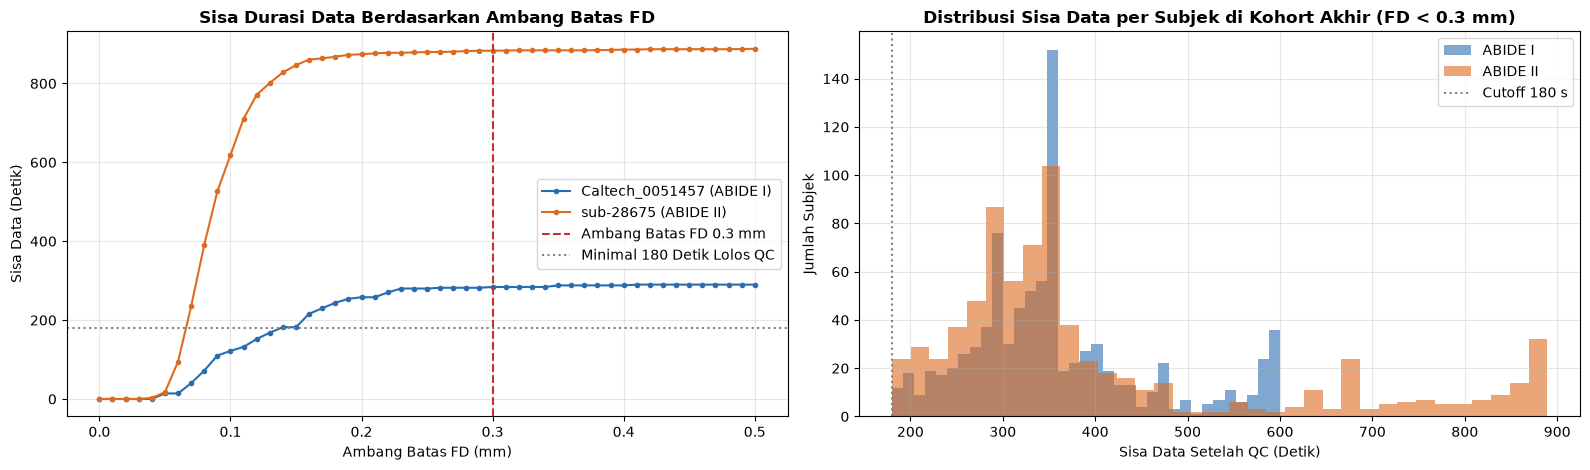

,total_frame,sisa_frame,sisa_detik,fd_rata_sisa
dataset,,,,
ABIDE I,200.000000,172.000000,346.000000,0.110000
ABIDE II,180.000000,155.500000,342.140000,0.110000


In [8]:
def kurva_sisa(gerak_dict):
    ambang = sorted(gerak_dict.keys())
    detik = [float(gerak_dict[a].remaining_seconds) for a in ambang]
    return np.array(ambang), np.array(detik)

d2 = kohort[kohort["dataset"] == "abide2"].iloc[0]
CONTOH2 = kohort[kohort["sub"] == "sub-28675"].iloc[0] if (kohort["sub"] == "sub-28675").any() else d2
gerak2 = baca_gerak(DCAN_DIR / "abide2" / CONTOH2["sub"] / Path(CONTOH2["berkas_gerak"]).name)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

for g, nama, w in [(gerak, f"{CONTOH['FILE_ID']} (ABIDE I)", "#2B6CB0"), (gerak2, f"{CONTOH2['sub']} (ABIDE II)", "#DD6B20")]:
    a, s = kurva_sisa(g)
    axes[0].plot(a, s, marker=".", color=w, label=nama, lw=1.5)

axes[0].axvline(0.3, color="#C53030", ls="--", label="Ambang Batas FD 0.3 mm")
axes[0].axhline(180, color="gray", ls=":", label="Minimal 180 Detik Lolos QC")
axes[0].set_xlabel("Ambang Batas FD (mm)")
axes[0].set_ylabel("Sisa Data (Detik)")
axes[0].set_title("Sisa Durasi Data Berdasarkan Ambang Batas FD", fontweight="bold")
axes[0].legend()
axes[0].grid(alpha=0.3)

for ds, w, label_ds in [("abide1", "#2B6CB0", "ABIDE I"), ("abide2", "#DD6B20", "ABIDE II")]:
    axes[1].hist(kohort.loc[kohort["dataset"] == ds, "sisa_detik"], bins=35, alpha=0.6, color=w, label=label_ds)

axes[1].axvline(180, color="gray", ls=":", label="Cutoff 180 s")
axes[1].set_xlabel("Sisa Data Setelah QC (Detik)")
axes[1].set_ylabel("Jumlah Subjek")
axes[1].set_title("Distribusi Sisa Data per Subjek di Kohort Akhir (FD < 0.3 mm)", fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / "01b_4_masker_gerakan.png", dpi=150, bbox_inches="tight")
plt.show()

display(
    kohort.groupby("dataset")[["total_frame", "sisa_frame", "sisa_detik", "fd_rata_sisa"]]
    .median().round(2)
    .rename(index={"abide1": "ABIDE I", "abide2": "ABIDE II"})
    .style.set_caption("Median Metrik Gerakan Subjek Kohort Akhir")
)

## 9. Contoh Subjek ABIDE II & Komputasi Matriks FC

ABIDE II mencakup protokol pemindaian modern dengan **akselerasi Multiband ($TR = 0.475\text{ detik}$)**, menghasilkan jumlah frame waktu yang jauh lebih banyak.

- **Kiri**: Sinyal tiga wilayah otak pasca-DCAN pada interval waktu rapat.
- **Kanan**: Matriks **Functional Connectivity (FC)** $379 \times 379$ parcel (korelasi Pearson) yang dihitung dari frame lolos QC ($\text{FD} < 0.3\text{ mm}$). Matriks ini merupakan fitur dasar bagi Skenario S1–S4.

,Subjek,Situs Asal,TR (detik),Total Frame,Frame Dipakai (FD < 0.3),Durasi Dipakai (detik)
0,Caltech_0051457 (ABIDE I),CALTECH,2.0,150,142,284.0
1,sub-28675 (ABIDE II),ABIDEII-ONRC_2,0.5,1894,1859,883.0


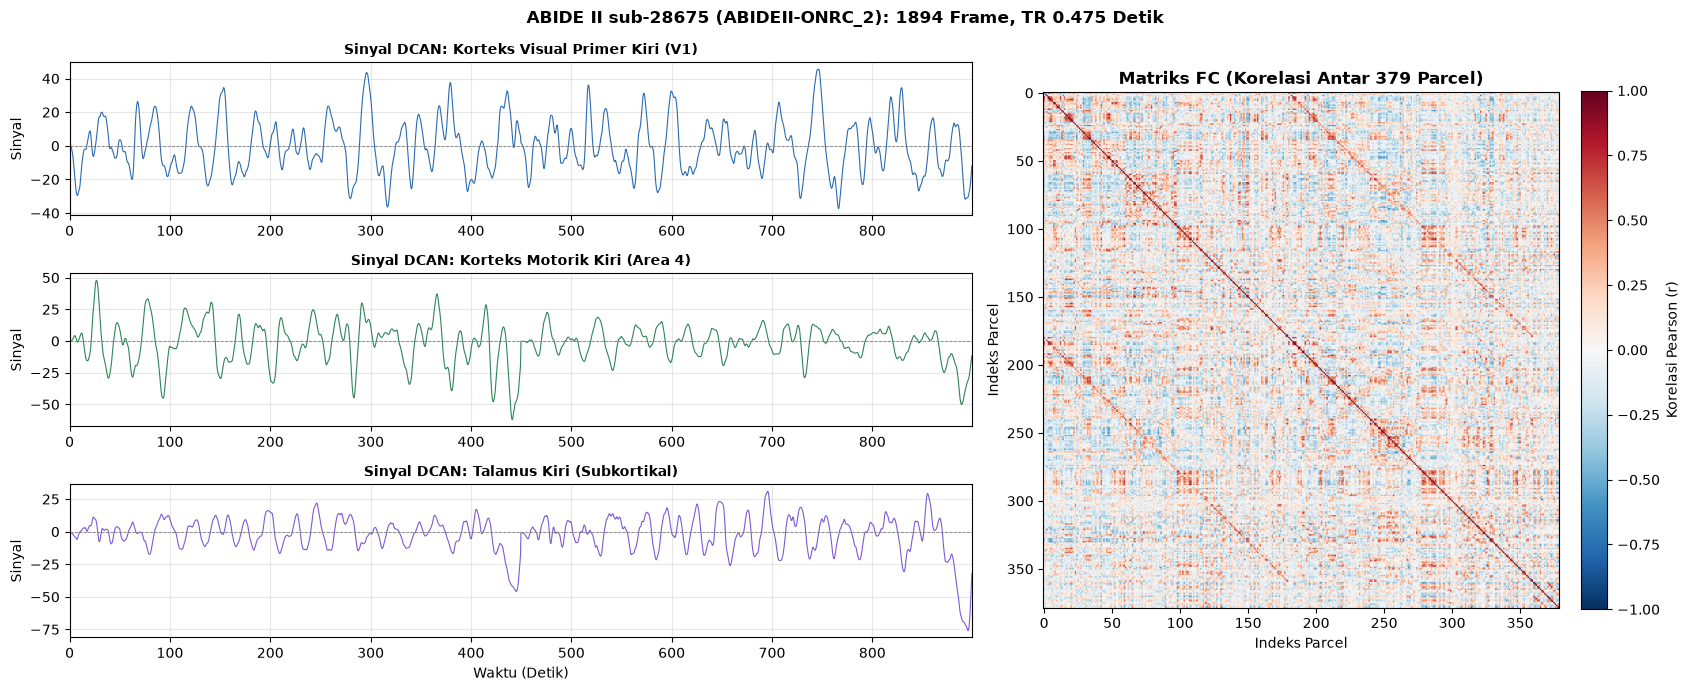

In [9]:
d_dcan2 = DCAN_DIR / "abide2" / CONTOH2["sub"]
ts2 = nib.load(cari(d_dcan2, "*HCP2016*_timeseries.ptseries.nii"))
TS2 = ts2.get_fdata()
pakai2 = (np.asarray(gerak2[0.3].frame_removal).astype(int) == 0)
FC2 = np.corrcoef(TS2[pakai2].T)

display(pd.DataFrame({
    "Subjek": [CONTOH["FILE_ID"] + " (ABIDE I)", CONTOH2["sub"] + " (ABIDE II)"],
    "Situs Asal": [CONTOH["situs"], CONTOH2["situs"]],
    "TR (detik)": [float(ax_waktu.step), float(ts2.header.get_axis(0).step)],
    "Total Frame": [TS.shape[0], TS2.shape[0]],
    "Frame Dipakai (FD < 0.3)": [int((~dibuang).sum()), int(pakai2.sum())],
    "Durasi Dipakai (detik)": [float(gerak[0.3].remaining_seconds), float(gerak2[0.3].remaining_seconds)]
}).round(1))

fig = plt.figure(figsize=(17, 7))
gs = fig.add_gridspec(len(PARCEL_CONTOH), 2, width_ratios=[1.6, 1])
t2 = np.arange(TS2.shape[0]) * float(ts2.header.get_axis(0).step)
idx2 = {n: list(ts2.header.get_axis(1).name).index(n) for n in PARCEL_CONTOH}

for i, ((n, label), w) in enumerate(zip(PARCEL_CONTOH.items(), ["#2B6CB0", "#2F855A", "#805AD5"])):
    ax = fig.add_subplot(gs[i, 0])
    ax.plot(t2, TS2[:, idx2[n]], color=w, lw=0.8)
    ax.axhline(0, color="gray", lw=0.6, linestyle="--")
    ax.set_ylabel("Sinyal")
    ax.grid(alpha=0.3)
    ax.set_xlim(0, t2[-1])
    ax.set_title(f"Sinyal DCAN: {label}", fontweight="bold", fontsize=10)
    if i == len(PARCEL_CONTOH) - 1:
        ax.set_xlabel("Waktu (Detik)")

ax_fc = fig.add_subplot(gs[:, 1])
im = ax_fc.imshow(FC2, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(im, ax=ax_fc, fraction=0.046, pad=0.04, label="Korelasi Pearson (r)")
ax_fc.set_title("Matriks FC (Korelasi Antar 379 Parcel)", fontweight="bold")
ax_fc.set_xlabel("Indeks Parcel")
ax_fc.set_ylabel("Indeks Parcel")

fig.suptitle(f"ABIDE II {CONTOH2['sub']} ({CONTOH2['situs']}): {TS2.shape[0]} Frame, TR {ts2.header.get_axis(0).step:.3f} Detik", fontweight="bold")
plt.tight_layout()
fig.savefig(FIG_DIR / "01b_5_contoh_abide2.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Karakteristik Akuisisi Multi-Situs ABIDE II

Tabel dan grafik di bawah memetakan parameter pemindaian (TR, jumlah subjek, durasi data bersih) dari 16 situs ABIDE II yang masuk ke dalam kohort akhir setelah QC gerakan:

,Subjek,ASD,TR,Frame_Total,Sisa_Detik,Usia,ASD (%)
situs,,,,,,,
ABIDEII-KKI_1,174,38,2.500000,156.000000,312.500000,10.390000,21.800000
ABIDEII-OHSU_1,93,37,2.500000,360.000000,790.000000,11.000000,39.800000
ABIDEII-NYU_1,69,41,2.000000,180.000000,336.000000,8.570000,59.400000
ABIDEII-SDSU_1,55,32,2.000000,180.000000,344.000000,13.000000,58.200000
ABIDEII-GU_1,55,23,2.000000,152.000000,280.000000,10.950000,41.800000
ABIDEII-ONRC_2,53,19,0.480000,1864.000000,473.100000,23.000000,35.800000
ABIDEII-IP_1,49,19,2.700000,255.000000,645.300000,19.330000,38.800000
ABIDEII-BNI_1,43,23,3.000000,120.000000,282.000000,41.000000,53.500000
ABIDEII-IU_1,37,17,0.810000,433.000000,343.900000,22.000000,45.900000


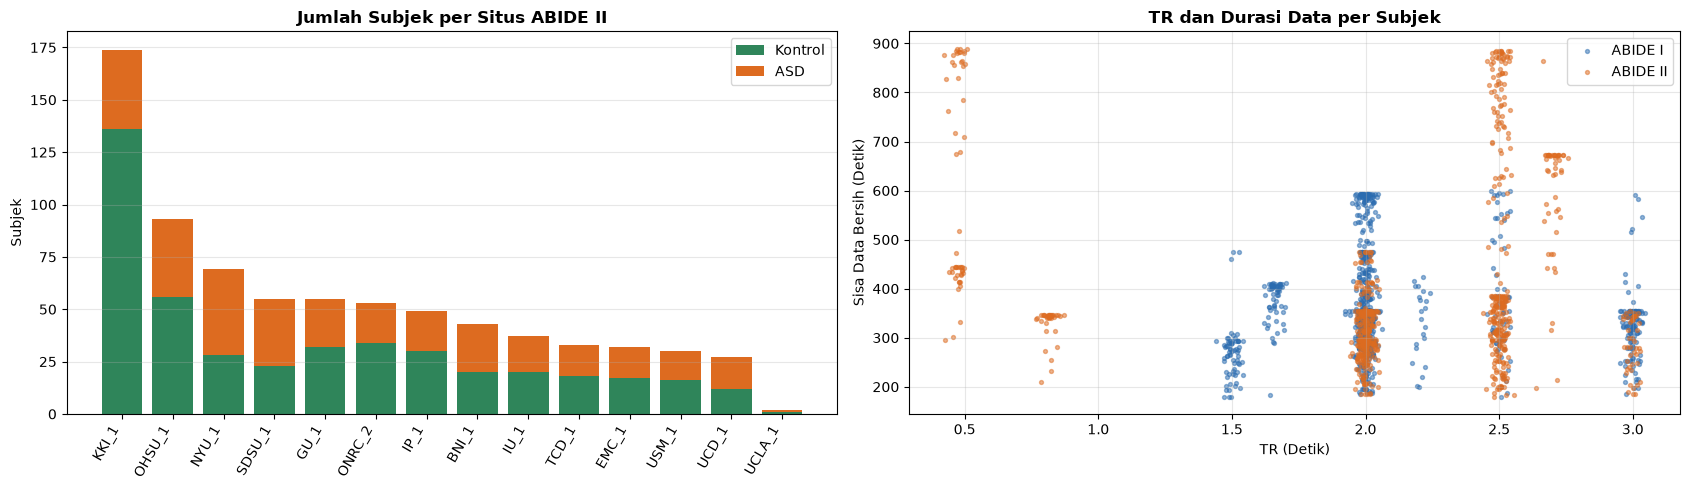

In [10]:
a2 = kohort[kohort["dataset"] == "abide2"]
per_situs = (
    a2.groupby("situs")
    .agg(
        Subjek=("label", "size"),
        ASD=("label", "sum"),
        TR=("TR", "median"),
        Frame_Total=("total_frame", "median"),
        Sisa_Detik=("sisa_detik", "median"),
        Usia=("usia", "median")
    )
    .sort_values("Subjek", ascending=False)
)
per_situs["ASD (%)"] = (per_situs["ASD"] / per_situs["Subjek"] * 100).round(1)
display(per_situs.round(2).style.set_caption(f"ABIDE II di kohort akhir: {len(a2)} subjek dari {a2['situs'].nunique()} situs"))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
x = np.arange(len(per_situs))
kontrol_cnt = per_situs["Subjek"] - per_situs["ASD"]

axes[0].bar(x, kontrol_cnt, color="#2F855A", label="Kontrol")
axes[0].bar(x, per_situs["ASD"], bottom=kontrol_cnt, color="#DD6B20", label="ASD")
axes[0].set_xticks(x)
axes[0].set_xticklabels([s.replace("ABIDEII-", "") for s in per_situs.index], rotation=60, ha="right")
axes[0].set_ylabel("Subjek")
axes[0].legend()
axes[0].set_title("Jumlah Subjek per Situs ABIDE II", fontweight="bold")
axes[0].grid(axis="y", alpha=0.3)

rng = np.random.default_rng(0)
for ds, w, label_ds in [("abide1", "#2B6CB0", "ABIDE I"), ("abide2", "#DD6B20", "ABIDE II")]:
    d = kohort[kohort["dataset"] == ds]
    jitter = rng.normal(0, 0.02, len(d))
    axes[1].scatter(d["TR"] + jitter, d["sisa_detik"], s=8, alpha=0.5, color=w, label=label_ds)

axes[1].set_xlabel("TR (Detik)")
axes[1].set_ylabel("Sisa Data Bersih (Detik)")
axes[1].set_title("TR dan Durasi Data per Subjek", fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / "01b_6_akuisisi_per_situs.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Data Fenotipik ABIDE II & Skrining Kebocoran Data (*Data Leakage*)

Fenotipik ABIDE II tersimpan per situs dalam berkas `participants.tsv`. Dari 19 situs ABIDE II, sebanyak **16 situs** memiliki berkas ini di server (3 situs lainnya tanpa metadata label dieliminasi).

> **Pencegahan Data Leakage**: Sama seperti pada ABIDE I (notebook 03), instrumen tes klinis autisme (**ADOS**, **ADI-R**, **SRS**) **TIDAK DIGUNAKAN** sebagai fitur prediksi. Kolom tersebut hanya diisi untuk kelompok pasien ASD sehingga menggunakannya akan menyebabkan kebocoran label (*target leakage*). Fitur yang diizinkan hanya demografi umum non-bocor: usia, jenis kelamin, dan FIQ.

participants.tsv: 1007 subjek dari 16 situs, 349 kolom


,Subjek,Usia (rata-rata ± SD),Rentang usia,Perempuan (%),FIQ (rata-rata ± SD),FIQ kosong
Diagnosis,,,,,,
ASD,474,14.9 ± 9.3,5.1 – 62.0,15.400000,106.5 ± 17.0,41
Kontrol,533,14.9 ± 9.5,5.9 – 64.0,32.800000,114.8 ± 12.9,57


,dx_group,age_at_scan,sex,fiq,viq,piq,handedness_category
Kosong (%),0.000000,0.000000,0.000000,9.700000,31.300000,24.000000,2.300000


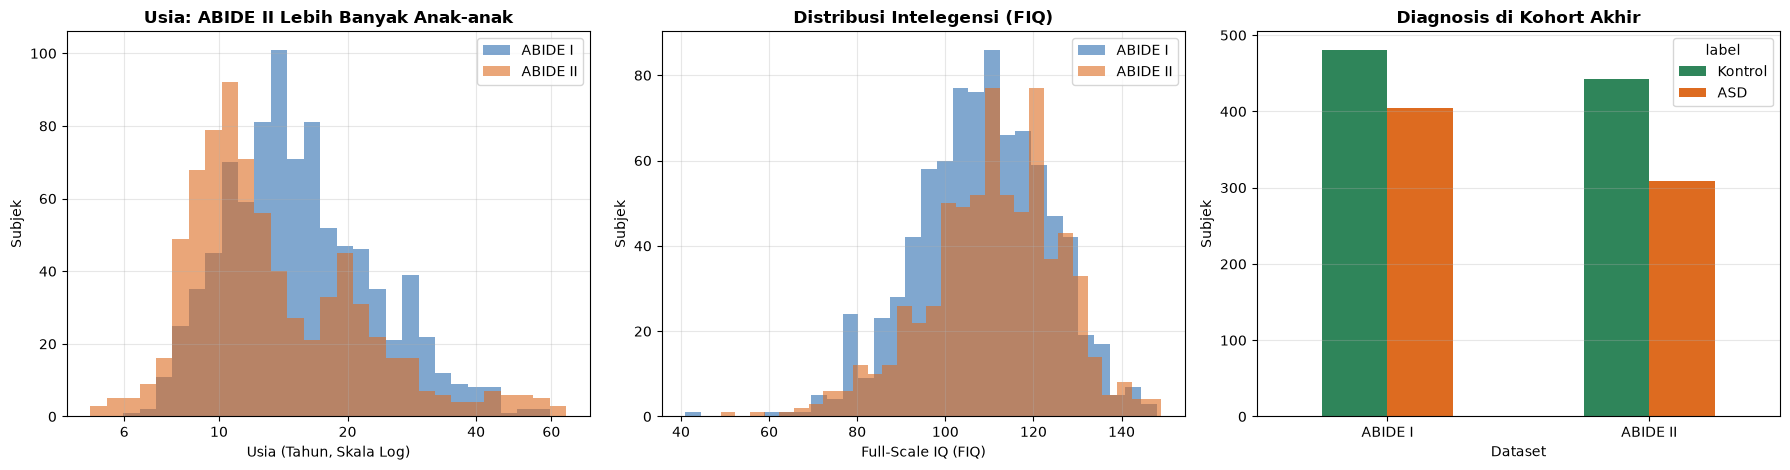

In [11]:
fen = []
for f in sorted(glob.glob(str(DCAN_DIR / "abide2_participants" / "*.tsv"))):
    fen.append(pd.read_csv(f, sep="\t", encoding="latin-1").rename(columns=lambda c: c.strip()))
fen = pd.concat(fen, ignore_index=True)
fen["fiq"] = fen["fiq"].where(fen["fiq"] > 0)
fen["Diagnosis"] = fen["dx_group"].map({1: "ASD", 2: "Kontrol"})

print(f"participants.tsv: {len(fen)} subjek dari {fen['site_id'].nunique()} situs, {fen.shape[1]} kolom")

desk = pd.DataFrame({
    "Subjek": fen.groupby("Diagnosis").size(),
    "Usia (rata-rata ± SD)": fen.groupby("Diagnosis")["age_at_scan"].agg(lambda s: f"{s.mean():.1f} ± {s.std():.1f}"),
    "Rentang usia": fen.groupby("Diagnosis")["age_at_scan"].agg(lambda s: f"{s.min():.1f} – {s.max():.1f}"),
    "Perempuan (%)": fen.groupby("Diagnosis")["sex"].agg(lambda s: (s == 2).mean() * 100),
    "FIQ (rata-rata ± SD)": fen.groupby("Diagnosis")["fiq"].agg(lambda s: f"{s.mean():.1f} ± {s.std():.1f}"),
    "FIQ kosong": fen.groupby("Diagnosis")["fiq"].agg(lambda s: int(s.isna().sum())),
})
display(desk.round(1).style.set_caption("Fenotipik ABIDE II (Sebelum QC)"))

kosong = (fen[["dx_group", "age_at_scan", "sex", "fiq", "viq", "piq", "handedness_category"]].isna().mean() * 100).round(1)
display(kosong.rename("Kosong (%)").to_frame().T.style.set_caption("Persentase Nilai Kosong Kolom Utama"))

banding = kohort.assign(Dataset=kohort["dataset"].map({"abide1": "ABIDE I", "abide2": "ABIDE II"}))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

for ds, w in [("ABIDE I", "#2B6CB0"), ("ABIDE II", "#DD6B20")]:
    d = banding[banding["Dataset"] == ds]
    axes[0].hist(d["usia"], bins=np.logspace(np.log10(5), np.log10(65), 30), alpha=0.6, color=w, label=ds)
    axes[1].hist(d["fiq"].dropna(), bins=30, alpha=0.6, color=w, label=ds)

axes[0].set_xscale("log")
axes[0].set_xticks([6, 10, 20, 40, 60])
axes[0].set_xticklabels(["6", "10", "20", "40", "60"])
axes[0].minorticks_off()
axes[0].set_xlabel("Usia (Tahun, Skala Log)")
axes[0].set_ylabel("Subjek")
axes[0].set_title("Usia: ABIDE II Lebih Banyak Anak-anak", fontweight="bold")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_xlabel("Full-Scale IQ (FIQ)")
axes[1].set_ylabel("Subjek")
axes[1].set_title("Distribusi Intelegensi (FIQ)", fontweight="bold")
axes[1].legend()
axes[1].grid(alpha=0.3)

tab = banding.groupby(["Dataset", "label"]).size().unstack().rename(columns={0: "Kontrol", 1: "ASD"})
tab.plot.bar(ax=axes[2], color=["#2F855A", "#DD6B20"], rot=0)
axes[2].set_title("Diagnosis di Kohort Akhir", fontweight="bold")
axes[2].set_xlabel("Dataset")
axes[2].set_ylabel("Subjek")
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / "01b_7_fenotipik_abide1_vs_abide2.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Alur Seleksi Subjek: Dari Repositori Server ke Kohort Akhir ($N = 1.638$)

Kriteria berikut diterapkan secara berurutan di Notebook 09 secara apriori (sebelum melihat performa klasifikasi model):

,Kriteria (kumulatif),ABIDE I,ABIDE II,Total,ASD / kontrol
0,Fenotipik tersedia (ABIDE I: kohort_final),987,1007,1994,950 / 1044
1,Time series DCAN 3 atlas lengkap dan valid,979,928,1907,906 / 1001
2,"Bukan situs satu kelas (KUL_3, NYU_2)",979,873,1852,851 / 1001
3,"QC gerakan: FD < 0.3 mm, sisa ≥ 180 detik",886,752,1638,714 / 924


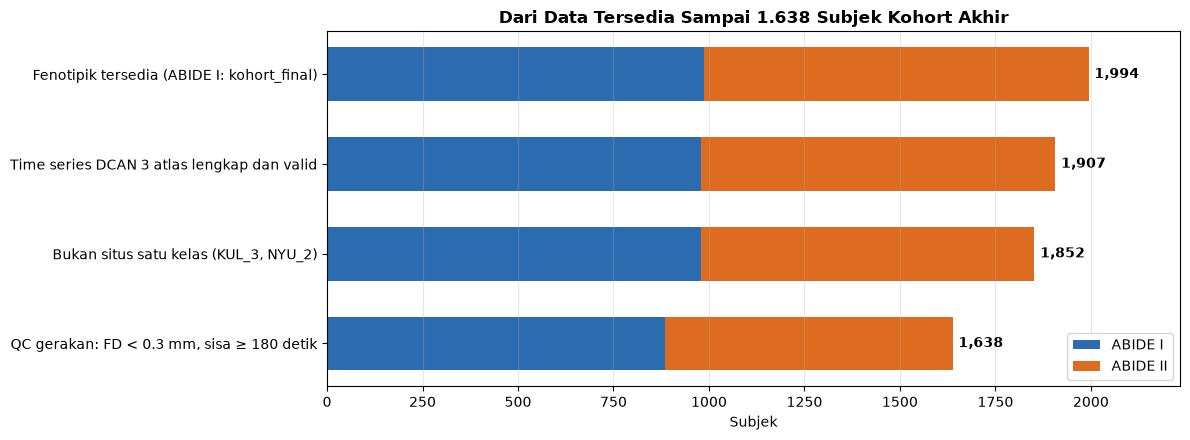

In [12]:
alur = pd.read_csv(TABEL_DIR / "21_alur_kohort_dcan.csv")
display(alur.style.set_caption("Alur Retensi Kohort ABIDE I + II (dari Notebook 21)"))

fig, ax = plt.subplots(figsize=(12, 4.5))
y_pos = np.arange(len(alur))[::-1]

ax.barh(y_pos, alur["ABIDE I"], color="#2B6CB0", label="ABIDE I", height=0.6)
ax.barh(y_pos, alur["ABIDE II"], left=alur["ABIDE I"], color="#DD6B20", label="ABIDE II", height=0.6)

for yy, tot in zip(y_pos, alur["Total"]):
    ax.text(tot + 15, yy, f"{tot:,}", va="center", fontweight="bold")

ax.set_yticks(y_pos)
ax.set_yticklabels(alur.iloc[:, 0])
ax.set_xlabel("Subjek")
ax.legend(loc="lower right")
ax.set_xlim(0, alur["Total"].max() * 1.12)
ax.set_title("Dari Data Tersedia Sampai 1.638 Subjek Kohort Akhir", fontweight="bold")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
fig.savefig(FIG_DIR / "01b_8_alur_kohort.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Kesimpulan Penting dari Eksplorasi Turunan DCAN

1. **Unifikasi Pipeline Menghilangkan Efek Batch Metodologis**:
   - Pemrosesan ABIDE I dan ABIDE II menggunakan pipeline tunggal ABCD-HCP DCAN menghilangkan variasi algoritma antar dataset, sehingga ukuran sampel dapat ditingkatkan menjadi **1.638 subjek**.
2. **Keunggulan Ruang Analisis Permukaan (*Surface-Based fsLR32k*)**:
   - Berbeda dengan voxel volumetrik mentah, representasi mesh korteks menjaga topologi lipatan otak dan menyediakan fitur morfometri biologis (ketebalan, sulkus, kelengkungan) yang bebas dari artefak pencampuran sinyal (*partial volume effect*).
3. **Pembersihan Sinyal & Sensor Gerakan Kepala Ketat**:
   - Eliminasi baseline drift dan motion masking ($\text{FD} < 0.3\text{ mm}$ dengan sisa durasi $\ge 180\text{ detik}$) memastikan matriks konektivitas fungsional (FC) mencerminkan konektivitas saraf intrinsik murni, bukan artefak gerakan subjek autisme.
4. **Kesiapan Data untuk Pemodelan Graph Neural Network (GNN)**:
   - Matriks FC 379 parcel (rs-fMRI), fitur morfometri korteks (sMRI), dan variabel fenotipik non-bocor menjadi bahan masukan siap pakai bagi arsitektur GATv2 pada Skenario S1 hingga S4.

---

### Peta Keterhubungan Notebook Berikutnya

```
01 / 01b  ──► Pemahaman data fisik mentah (raw NIfTI) & turunan terstandardisasi DCAN
02 / 03   ──► Analisis eksploratif (EDA) & pembersihan data fenotipik
21        ──► Filter QC gerakan (FD < 0.3 mm) & pembagian lipatan Stratified 5-Fold CV
22        ──► Ekstraksi matriks FC Tangent (Gordon 352, HCP 379, Markov 205)
23        ──► Ekstraksi fitur morfometri korteks fsLR32k & kopling struktur-fungsi
25–28     ──► Eksperimen pemodelan Graph Attention Network (GATv2): Skenario S1–S4
```